# **Final Task for Data Analysis**
Davide Orecchioni, 584164

# Importing data

In [ ]:
# !gdown 1Ria7NV8bR1JkjCJhapUse3GvJ8U8rJ7w
# !unzip EigenWorms.zip
!gdown 1WDQzN0jzQS0ICooDadUmaaVms-d_8U6Y
!gdown 13fAClq8NhguvttzCyy29mtnq-f-9QmXD
!gdown 1CqM6kvI8CN2O7zS-psmyl_1qQ2G-M0d7
!gdown 1xDPXje03M2Lz2XAYNf8KqmFYnDA2OBgS
!gdown 1eayA-a_Ai_VbPS6vUSbxICjt-SYJtDWc
!gdown 1RCBoBWui0IvRivFrqEYMGwqembUEqBJk
!gdown 1geG4jQ8CoQXVPs4x-a0zKy9aYaVcICo7
!gdown 1j6TqqPSAx2ep6kcE-EKYjVhI4jXqjp-m
!gdown 1pu5zmry88wBKOWEVYWkQ375s5NTYfEvI
!gdown 1FXVGrrEHvHmSNiSrbgHlKKwX3P13PbSP
!gdown 1UpPgsV5ORS3Q0qdSs0GWzpkjE5P0aF08
!gdown 1t4fNV18wGcuYeWuXVFnPzkAyey-wnNKe

Downloading...
From: https://drive.google.com/uc?id=1WDQzN0jzQS0ICooDadUmaaVms-d_8U6Y
To: /content/EigenWormsDimension1_TEST.arff
100% 22.7M/22.7M [00:00<00:00, 72.7MB/s]
Downloading...
From: https://drive.google.com/uc?id=13fAClq8NhguvttzCyy29mtnq-f-9QmXD
To: /content/EigenWormsDimension1_TRAIN.arff
100% 22.3M/22.3M [00:00<00:00, 53.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=1CqM6kvI8CN2O7zS-psmyl_1qQ2G-M0d7
To: /content/EigenWormsDimension2_TEST.arff
100% 22.8M/22.8M [00:00<00:00, 75.9MB/s]
Downloading...
From: https://drive.google.com/uc?id=1xDPXje03M2Lz2XAYNf8KqmFYnDA2OBgS
To: /content/EigenWormsDimension2_TRAIN.arff
100% 22.3M/22.3M [00:00<00:00, 72.9MB/s]
Downloading...
From: https://drive.google.com/uc?id=1eayA-a_Ai_VbPS6vUSbxICjt-SYJtDWc
To: /content/EigenWormsDimension3_TEST.arff
100% 22.8M/22.8M [00:00<00:00, 62.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=1RCBoBWui0IvRivFrqEYMGwqembUEqBJk
To: /content/EigenWormsDimension3_TRAIN.arff
100% 22.2M/2

In [ ]:
import pandas as pd
from scipy.io import arff
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn import linear_model
from sklearn.neighbors import KNeighborsClassifier as knn
from sklearn.ensemble import RandomForestClassifier
from sklearn import svm
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score as acc
from sklearn.metrics import precision_score as prec
from sklearn.metrics import recall_score as rec
from sklearn.metrics import f1_score as f1

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense
from tensorflow.keras.utils import to_categorical

N = 17984 # Number of entries of each of the 6 time series
n = 259 # Total number of instances at our disposal

In [ ]:
# FORMAT
# When using loadarff on the original files, the last column is a string of the form "'bX'" where X is a number from 1 to 5.
# We use this function to clean this up for easier reading.

def format(df):
    df = pd.DataFrame(df).set_axis([*range(N), 'strain'],axis=1)
    s = []
    strain = df['strain']
    for i in range(len(df)):
        l = str(strain[i])
        l=l.replace('b', '')
        l=l.replace('\'', '')
        s.append(int(l))
    S = pd.DataFrame(s, columns=['strain'], dtype=int)
    df.update(S)
    return df

# DATA LOADING
# We load the data using loadarff and the aforementioned format function. We store it in three lists;
# one with the original training data, one with the original testing data and one with all available instances.

train_D = []
test_D = []
full_D = []

for i in range(6):
    train, _ = arff.loadarff('EigenWormsDimension'+str(i+1)+'_TRAIN.arff')
    test, _ = arff.loadarff('EigenWormsDimension'+str(i+1)+'_TEST.arff')
    train = format(train)
    test = format(test)
    train_D.append(train)
    test_D.append(test)
    full_D.append(pd.concat([train, test]).reset_index(drop=True))
    print(i+1)

1
2
3
4
5
6


# Dataset Inspection

In [ ]:
# Inspection of classes
y = train_D[0]['strain']
print('Training data: '+str(len(y))+' cases')
print('Class 1: '+str(sum(y == 1)))
print('Class 2: '+str(sum(y == 2)))
print('Class 3: '+str(sum(y == 3)))
print('Class 4: '+str(sum(y == 4)))
print('Class 5: '+str(sum(y == 5)))

w = test_D[0]['strain']
print('\nTest data: '+str(len(w))+' cases')
print('Class 1: '+str(sum(w == 1)))
print('Class 2: '+str(sum(w == 2)))
print('Class 3: '+str(sum(w == 3)))
print('Class 4: '+str(sum(w == 4)))
print('Class 5: '+str(sum(w == 5)))

Training data: 128 cases
Class 1: 55
Class 2: 22
Class 3: 17
Class 4: 22
Class 5: 12

Test data: 131 cases
Class 1: 55
Class 2: 22
Class 3: 18
Class 4: 23
Class 5: 13


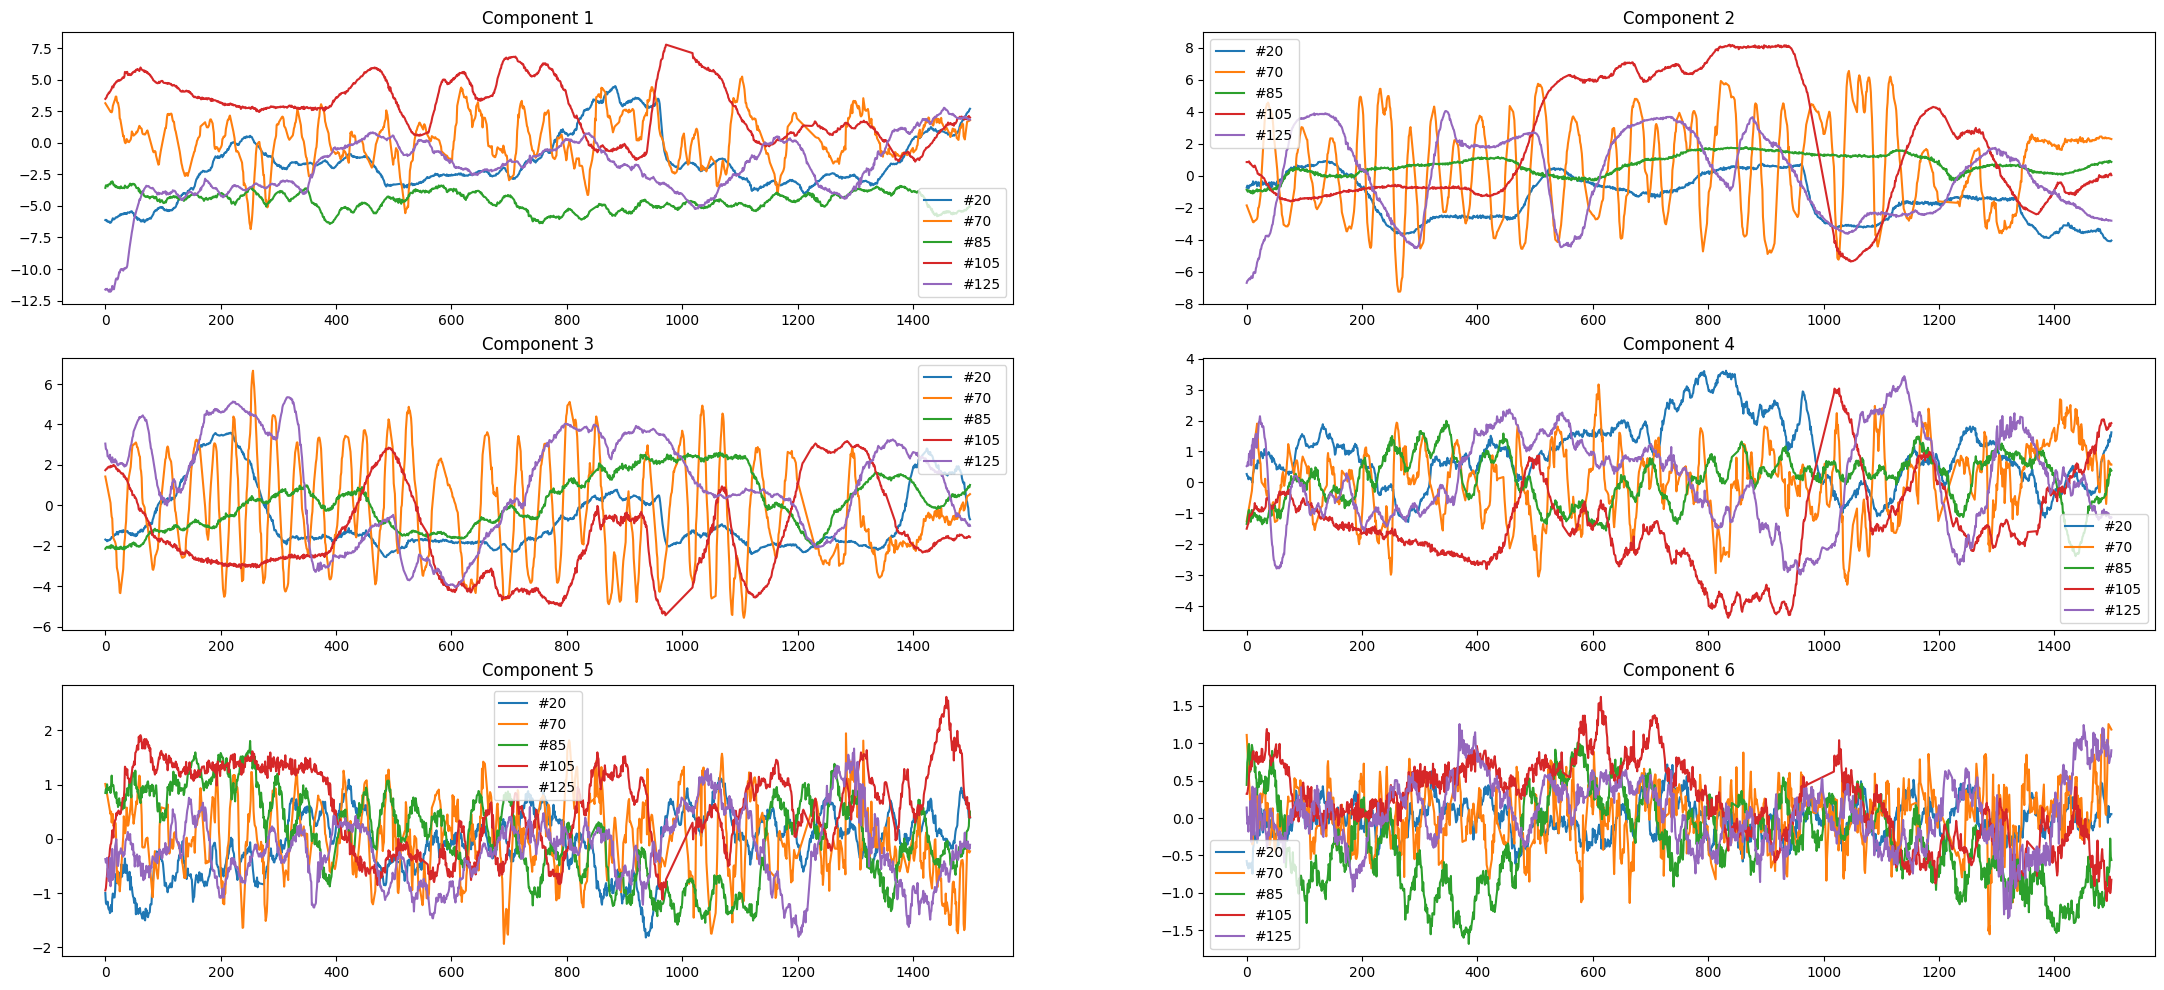

In [ ]:
# Visual inspection of the data selecting a worm from each class and a time window

plt.rcParams["figure.figsize"] = (27,12)

worms = [20, 70, 85, 105, 125]
window = range(1500)

for i in range(6):
    plt.subplot(3, 2, i+1)
    plt.title('Component '+str(i+1))
    for j in worms:
        df = train_D[i]
        plt.plot(window,df.loc[j, window], label='#'+str(j))
    plt.legend()
plt.show()

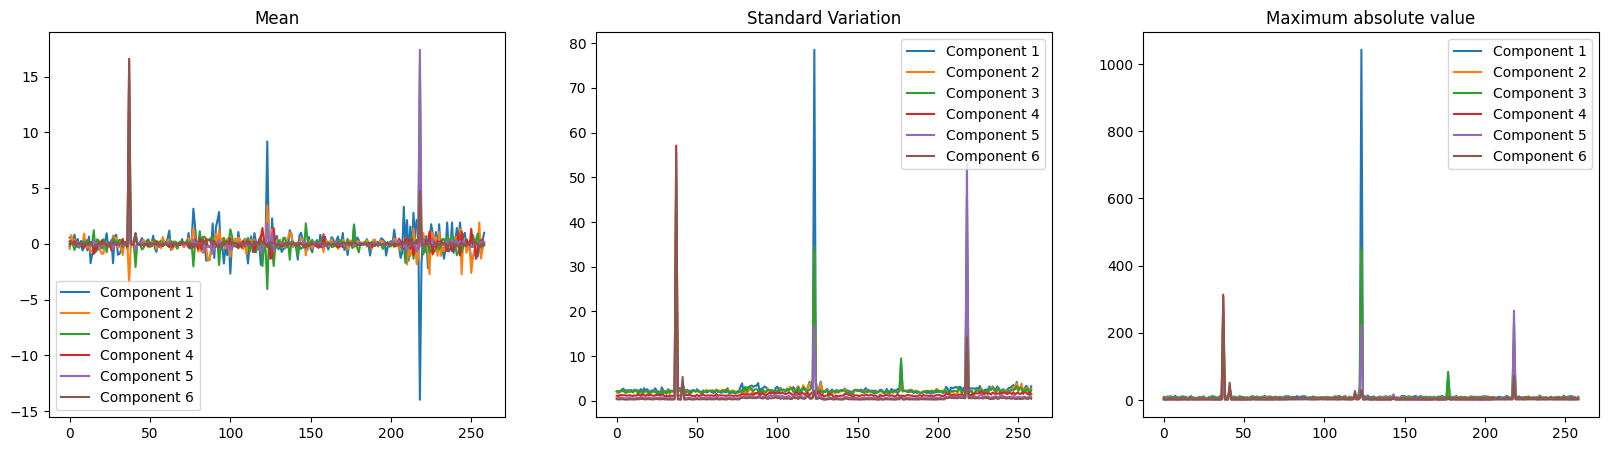

In [ ]:
# Searching for outliers

M = np.zeros([n, 6])
S = np.zeros([n, 6])
A = np.zeros([n, 6])

for i in range(n):
    for j in range(6):
        df = full_D[j].loc[i, range(N)]
        M[i, j] = df.mean()
        S[i, j] = df.std()
        A[i, j] = np.abs(df).max()

plt.rcParams["figure.figsize"] = (20,5)

plt.subplot(1, 3, 1)
plt.title("Mean")
for j in range(6):
    plt.plot(M[:, j], label = 'Component '+str(j+1))
plt.legend()
plt.subplot(1, 3, 2)
plt.title("Standard Variation")
for j in range(6):
    plt.plot(S[:, j], label = 'Component '+str(j+1))
plt.legend()
plt.subplot(1, 3, 3)
plt.title("Maximum absolute value")
for j in range(6):
    plt.plot(A[:, j], label = 'Component '+str(j+1))
plt.legend()

#37: Class 1
#41: Class 1
#123: Class 5
#177: Class 1
#218: Class 3


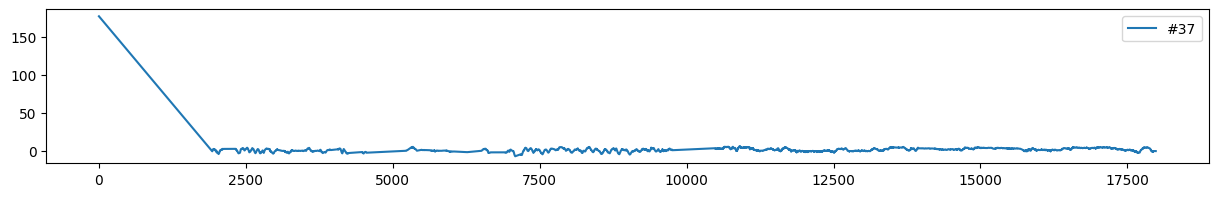

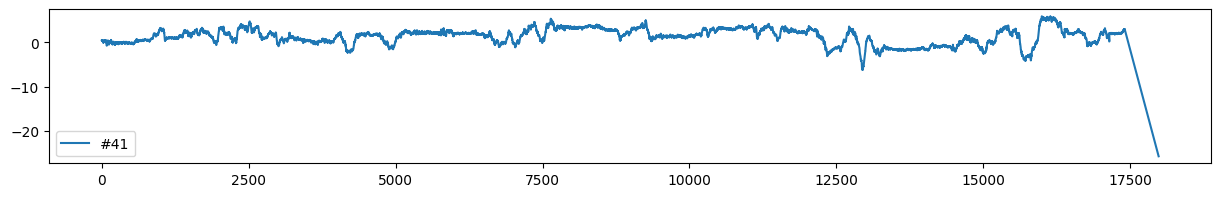

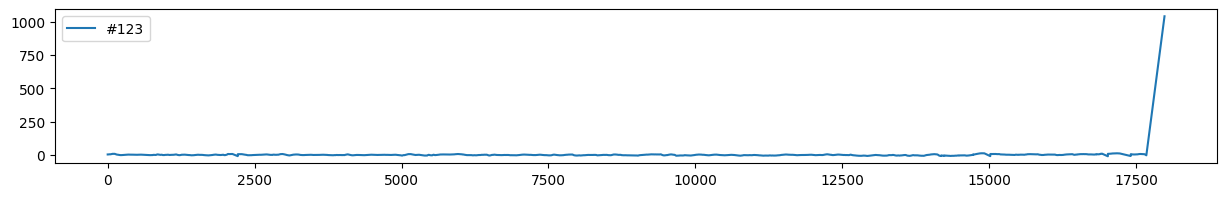

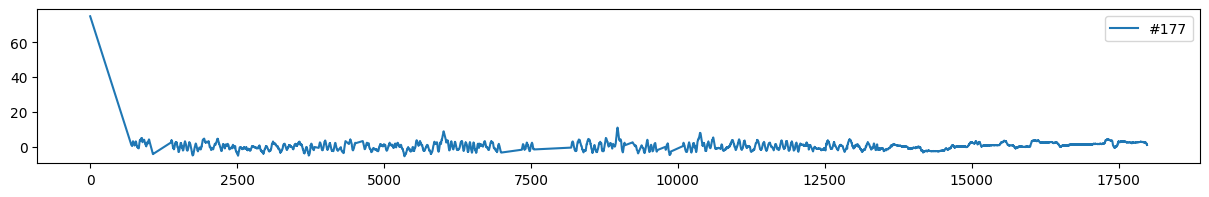

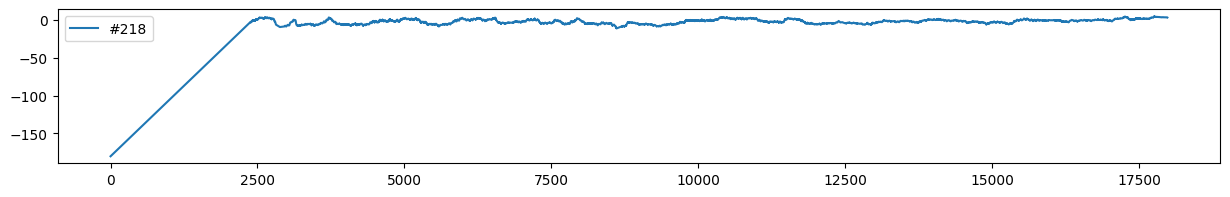

In [ ]:
# Visualizing outliers

for i in [37, 41, 123, 128+49, 128+90]:
  print('#'+str(i)+': Class '+str(full_D[0].loc[i, 'strain']))

plt.rcParams["figure.figsize"] = (15,2)

plt.plot(full_D[0].loc[37, range(N)], label = '#37')
plt.legend()
plt.figure()
plt.plot(full_D[0].loc[41, range(N)], label = '#41')
plt.legend()
plt.figure()
plt.plot(full_D[0].loc[123, range(N)], label = '#123')
plt.legend()
plt.figure()
plt.plot(full_D[0].loc[128+49, range(N)], label = '#177')
plt.legend()
plt.figure()
plt.plot(full_D[0].loc[128+90, range(N)], label = '#218')
plt.legend()

# Classical methods

In [ ]:
# LOAD
# We use the same train/test split as the original data. X and y correspond, respectively, to the features and labels of the training data,
# and Z and w are the same for the test data. We also implement the following options:
# - Scale data with Standard normalization
# - Automatically drop outliers
# - Return binary versions of the labels for 0-1 classification
# - Holding out one component at a time

def scale(A):
    scaler = StandardScaler().fit(A)
    return scaler.transform(A)

def load(train_D = train_D, test_D = test_D, drop_outliers = True, rescale=False, binary = False, hold_out = -1):

    i = list(range(6))
    if hold_out > -1:
      i.remove(hold_out)

    X = train_D[i[0]][range(N)]
    Z = test_D[i[0]][range(N)]
    y = train_D[i[0]]['strain']
    w = test_D[i[0]]['strain']
    i.remove(i[0])

    for j in i:
        X = pd.concat([X, train_D[j][range(N)]], axis=1, ignore_index=True)
        Z = pd.concat([Z, test_D[j][range(N)]], axis=1, ignore_index=True)

    if drop_outliers:
        X = X.drop([37, 41, 123]).reset_index(drop=True)
        y = y.drop([37, 41, 123]).reset_index(drop=True)
        Z = Z.drop([49, 90]).reset_index(drop=True)
        w = w.drop([49, 90]).reset_index(drop=True)

    if rescale:
        X = scale(X)
        Z = scale(Z)

    if binary:
        y = (y == 1)
        w = (w == 1)

    y = np.array(y, dtype=int)
    w = np.array(w, dtype=int)

    n_train = 128 - 3*(drop_outliers)
    n_test = 131 - 2*(drop_outliers)

    return X, y, Z, w, n_train, n_test

In [ ]:
# Logistic Regression

X, y, Z, w, n_train, n_test = load()
y1 = (y == 1)
w1 = (w == 1)
logr = linear_model.LogisticRegression()
logr.fit(X,y)
pred = logr.predict(Z)
print('LR Results without rescaling:')
print('Class accuracy: '+str(100*sum(w == pred)/n_test)+'%')
print('1-5 accuracy: '+str(100*sum(w1 == (pred == 1))/n_test)+'%')
logr.fit(X,y1)
pred = logr.predict(Z)
print('0-1 accuracy: '+str(100*sum(w1 == pred)/n_test)+'%')

X, y, Z, w, n_train, n_test = load(rescale=True)
y1 = (y == 1)
w1 = (w == 1)
logr = linear_model.LogisticRegression()
logr.fit(X,y)
pred = logr.predict(Z)
print('\nLR Results with rescaling:')
print('Class accuracy: '+str(100*sum(w == pred)/n_test)+'%')
print('1-5 accuracy: '+str(100*sum(w1 == (pred == 1))/n_test)+'%')
logr.fit(X,y1)
pred = logr.predict(Z)
print('0-1 accuracy: '+str(100*sum(w1 == pred)/n_test)+'%')

LR Results without rescaling:
Class accuracy: 27.131782945736433%
1-5 accuracy: 58.13953488372093%
0-1 accuracy: 58.13953488372093%

LR Results with rescaling:
Class accuracy: 37.2093023255814%
1-5 accuracy: 62.01550387596899%
0-1 accuracy: 62.01550387596899%


In [ ]:
# Grid Search for optimal KNN hyperparameters

X, y, Z, w, n_train, n_test = load()
KNN = knn(1)
param = dict(n_neighbors = range(3, 11), weights=['uniform', 'distance'])
grid = GridSearchCV(KNN, param, cv=4, scoring='accuracy', return_train_score=False)
grid.fit(X, y)
print(grid.best_params_)

{'n_neighbors': 4, 'weights': 'distance'}


In [ ]:
# KNN

X, y, Z, w, n_train, n_test = load()
y1 = (y == 1)
w1 = (w == 1)
KNN = knn(4, weights='distance')
KNN.fit(X, y)
pred = KNN.predict(Z)
print('KNN Results without rescaling:')
print('Class accuracy: '+str(100*sum(w == pred)/n_test)+'%')
print('1-5 accuracy: '+str(100*sum(w1 == (pred == 1))/n_test)+'%')
KNN.fit(X, y1)
pred = KNN.predict(Z)
print('0-1 accuracy: '+str(100*sum(w1 == pred)/n_test)+'%')

X, y, Z, w, n_train, n_test = load(rescale=True)
y1 = (y == 1)
w1 = (w == 1)
KNN = knn(4, weights='distance')
KNN.fit(X, y)
pred = KNN.predict(Z)
print('\nKNN Results with rescaling:')
print('Class accuracy: '+str(100*sum(w == pred)/n_test)+'%')
print('1-5 accuracy: '+str(100*sum(w1 == (pred == 1))/n_test)+'%')
KNN.fit(X, y1)
pred = KNN.predict(Z)
print('0-1 accuracy: '+str(100*sum(w1 == pred)/n_test)+'%')

KNN Results without rescaling:
Class accuracy: 51.93798449612403%
1-5 accuracy: 54.263565891472865%
0-1 accuracy: 58.91472868217054%

KNN Results with rescaling:
Class accuracy: 51.16279069767442%
1-5 accuracy: 51.93798449612403%
0-1 accuracy: 51.93798449612403%


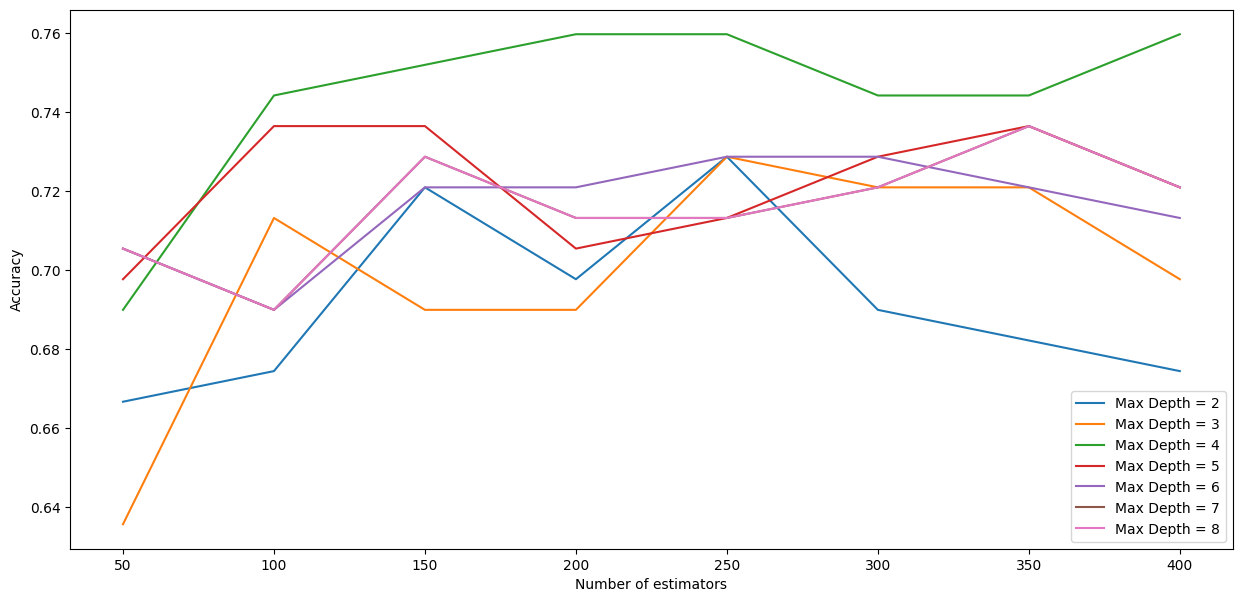

In [ ]:
# Parameter selection for RF
X, y, Z, w, n_train, n_test = load(binary=True)

plt.rcParams["figure.figsize"] = (15,7)
Acc = np.zeros([8, 7])
for i in range(8):
    for j in range(7):
        RF = RandomForestClassifier(n_estimators = 50*(i+1), max_depth=j+2, random_state=0)
        RF.fit(X, y)
        pred = RF.predict(Z)
        Acc[i, j] = sum(pred == w)/n_test
for j in range(7):
    plt.plot(range(50, 450, 50), Acc[:, j], label = 'Max Depth = '+str(j+2))
plt.xlabel('Number of estimators')
plt.ylabel('Accuracy')
plt.legend()


In [ ]:
# RF (Fixed seed)
RF = RandomForestClassifier(n_estimators = 250, max_depth=4, random_state=0)
X, y, Z, w, n_train, n_test = load()
y1 = (y == 1)
w1 = (w == 1)
RF.fit(X, y)
pred = RF.predict(Z)
print('Random Forest Results without rescaling:')
print('Class accuracy: '+str(100*sum(w == pred)/n_test)+'%')
print('1-5 accuracy: '+str(100*sum(w1 == (pred == 1))/n_test)+'%')
RF.fit(X, y1)
pred = RF.predict(Z)
print('0-1 accuracy: '+str(100*sum(w1 == pred)/n_test)+'%')

RF = RandomForestClassifier(n_estimators = 250, max_depth=4, random_state=0)
X, y, Z, w, n_train, n_test = load(rescale=True)
y1 = (y == 1)
w1 = (w == 1)
RF.fit(X, y)
pred = RF.predict(Z)
print('\nRandom Forest Results with rescaling:')
print('Class accuracy: '+str(100*sum(w == pred)/n_test)+'%')
print('1-5 accuracy: '+str(100*sum(w1 == (pred == 1))/n_test)+'%')
RF.fit(X, y1)
pred = RF.predict(Z)
print('0-1 accuracy: '+str(100*sum(w1 == pred)/n_test)+'%')

Random Forest Results without rescaling:
Class accuracy: 51.93798449612403%
1-5 accuracy: 51.93798449612403%
0-1 accuracy: 75.96899224806202%

Random Forest Results with rescaling:
Class accuracy: 51.16279069767442%
1-5 accuracy: 51.16279069767442%
0-1 accuracy: 70.54263565891473%


In [ ]:
# SVM

X, y, Z, w, n_train, n_test = load()
y1 = (y == 1)
w1 = (w == 1)
SVM=svm.SVC()
SVM.fit(X, y)
pred = SVM.predict(Z)
print('SVM results without scaling:')
print('Class accuracy: '+str(100*sum(w == pred)/n_test)+'%')
print('1-5 accuracy: '+str(100*sum(w1 == (pred == 1))/n_test)+'%')
SVM.fit(X, y1)
pred = SVM.predict(Z)
print('0-1 accuracy: '+str(100*sum(w1 == pred)/n_test)+'%')

X, y, Z, w, n_train, n_test = load(rescale=True)
y1 = (y == 1)
w1 = (w == 1)
SVM=svm.SVC()
SVM.fit(X, y)
pred = SVM.predict(Z)
print('\nSVM results with scaling:')
print('Class accuracy: '+str(100*sum(w == pred)/n_test)+'%')
print('1-5 accuracy: '+str(100*sum(w1 == (pred == 1))/n_test)+'%')
SVM.fit(X, y1)
pred = SVM.predict(Z)
print('0-1 accuracy: '+str(100*sum(w1 == pred)/n_test)+'%')

SVM results without scaling:
Class accuracy: 50.3875968992248%
1-5 accuracy: 50.3875968992248%
0-1 accuracy: 72.86821705426357%

SVM results with scaling:
Class accuracy: 65.11627906976744%
1-5 accuracy: 76.74418604651163%
0-1 accuracy: 82.17054263565892%


In [ ]:
# Train error

for i in [False, True]:
  X, y, Z, w, n_train, n_test = load(rescale=i)
  y1 = (y == 1)

  if i:
        print('\n\nTrain accuracy with rescaling:')
  else:
        print('Train accuracy without rescaling:')

  logr = linear_model.LogisticRegression(max_iter=100)
  logr.fit(X,y)
  pred = logr.predict(X)
  print('\nLogistic Regression:')
  print('Class accuracy: '+str(100*sum(y == pred)/n_test)+'%')
  print('1-5 accuracy: '+str(100*sum(y1 == (pred == 1))/n_test)+'%')
  logr.fit(X,y1)
  pred = logr.predict(X)
  print('0-1 accuracy: '+str(100*sum(y1 == pred)/n_test)+'%')

  KNN = knn(4, weights='distance')
  KNN.fit(X, y)
  pred = KNN.predict(X)
  print('\nKNN:')
  print('Class accuracy: '+str(100*sum(y == pred)/n_test)+'%')
  print('1-5 accuracy: '+str(100*sum(y1 == (pred == 1))/n_test)+'%')
  KNN.fit(X, y1)
  pred = KNN.predict(X)
  print('0-1 accuracy: '+str(100*sum(y1 == pred)/n_test)+'%')

  RF = RandomForestClassifier(n_estimators = 250, max_depth=4, random_state=0)
  RF.fit(X, y)
  pred = RF.predict(X)
  print('\nRandom Forest:')
  print('Class accuracy: '+str(100*sum(y == pred)/n_test)+'%')
  print('1-5 accuracy: '+str(100*sum(y1 == (pred == 1))/n_test)+'%')
  RF.fit(X, y1)
  pred = RF.predict(X)
  print('0-1 accuracy: '+str(100*sum(y1 == pred)/n_test)+'%')

  SVM=svm.SVC()
  SVM.fit(X, y)
  pred = SVM.predict(X)
  print('\nSVM:')
  print('Class accuracy: '+str(100*sum(y == pred)/n_test)+'%')
  print('1-5 accuracy: '+str(100*sum((y == 1) ==  (pred == 1))/n_test)+'%')
  SVM.fit(X, y1)
  pred = SVM.predict(X)
  print('0-1 accuracy: '+str(100*sum(y1 == pred)/n_test)+'%')

Train accuracy without rescaling:

Logistic Regression:
Class accuracy: 96.89922480620154%
1-5 accuracy: 96.89922480620154%
0-1 accuracy: 96.89922480620154%

KNN:
Class accuracy: 96.89922480620154%
1-5 accuracy: 96.89922480620154%
0-1 accuracy: 96.89922480620154%

Random Forest:
Class accuracy: 96.89922480620154%
1-5 accuracy: 96.89922480620154%
0-1 accuracy: 96.89922480620154%

SVM:
Class accuracy: 92.24806201550388%
1-5 accuracy: 92.24806201550388%
0-1 accuracy: 96.12403100775194%


Train accuracy with rescaling:

Logistic Regression:
Class accuracy: 96.89922480620154%
1-5 accuracy: 96.89922480620154%
0-1 accuracy: 96.89922480620154%

KNN:
Class accuracy: 96.89922480620154%
1-5 accuracy: 96.89922480620154%
0-1 accuracy: 96.89922480620154%

Random Forest:
Class accuracy: 96.89922480620154%
1-5 accuracy: 96.89922480620154%
0-1 accuracy: 96.89922480620154%

SVM:
Class accuracy: 96.12403100775194%
1-5 accuracy: 96.12403100775194%
0-1 accuracy: 96.89922480620154%


# Feature Reduction

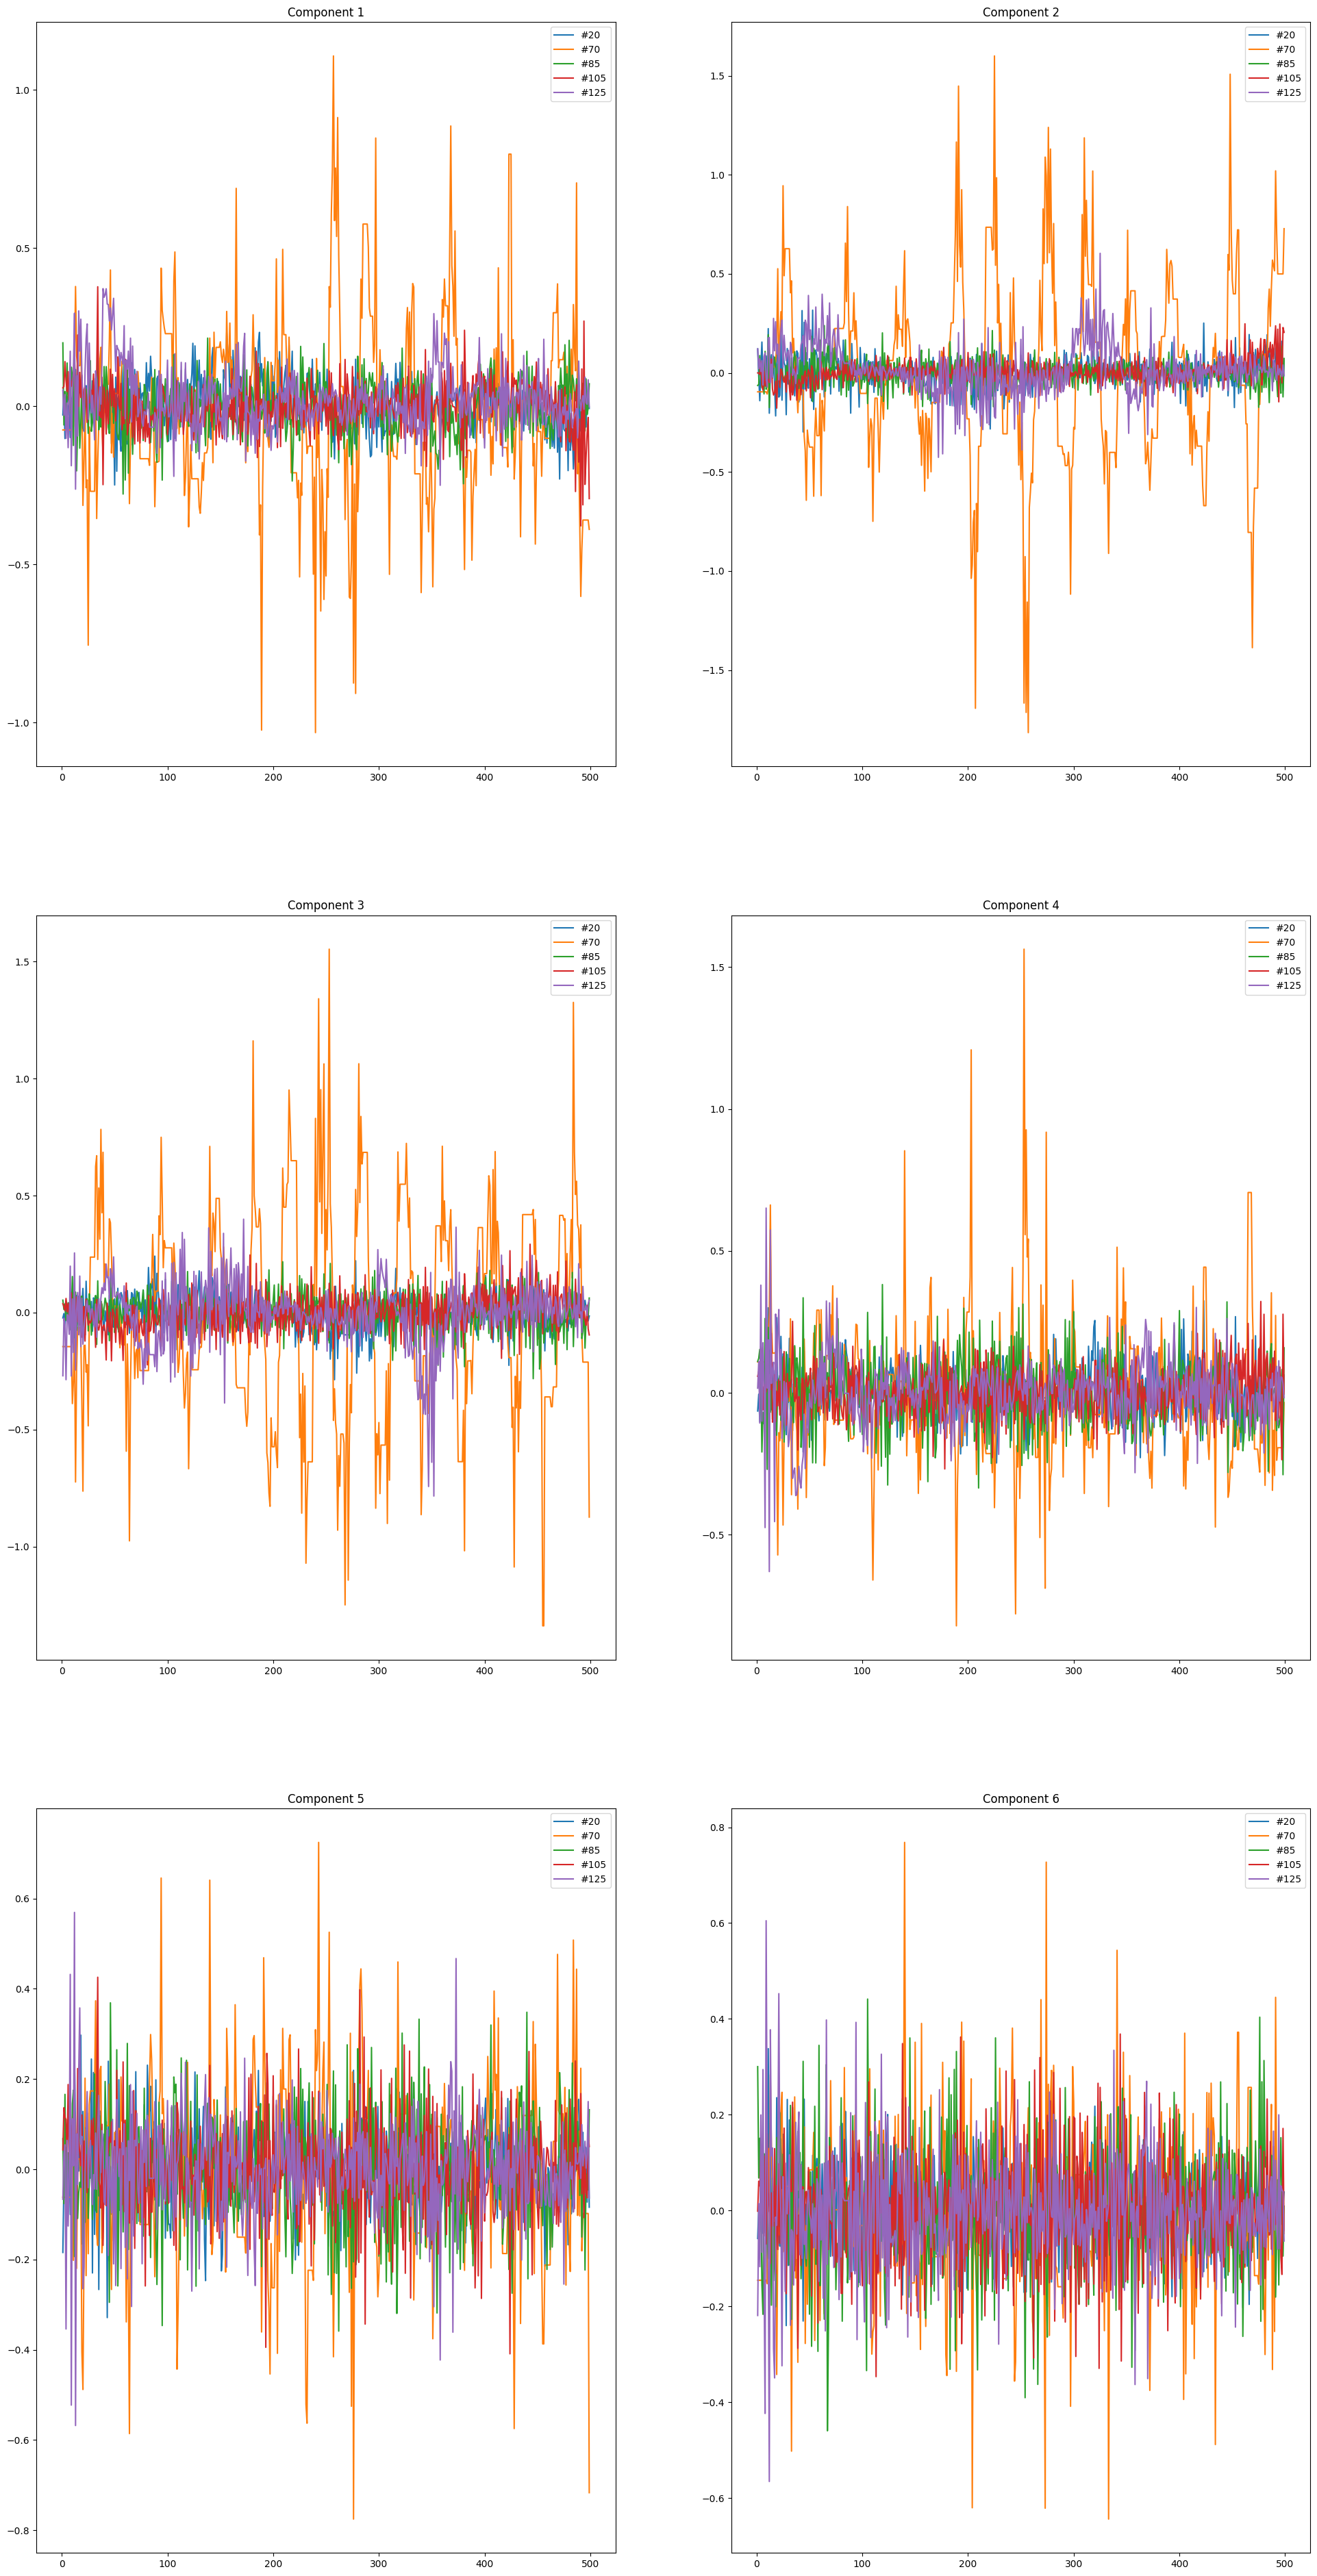

In [ ]:
# Visual inspection of the vectors of differences

plt.rcParams["figure.figsize"] = (24,48)

worms = [20, 70, 85, 105, 125]
window = range(500)

for i in range(6):
    plt.subplot(3, 2, i+1)
    plt.title('Component '+str(i+1))
    for j in worms:
        df = train_D[i]
        plt.plot(window,df.loc[j, window].diff(), label='#'+str(j))
    plt.legend()
plt.show()

In [ ]:
# REDUCE
# We take each time series and compute its mean, standard variation, maximum, and minimum.
# We also consider a measure of sudden change in subsequent values.
# This is done either with the standard test/train split (when test_size == 0) or for cross validation with a proportion
# (test_size) between 0 and 1. We also implement options for rescaling, dropping outliers and holding a component out.

def reduce(test_size = 0.0, drop_outliers = True, rescale = False, hold_out=-1):
    if test_size > 0:
        X0, y, Z0, w, n_train, n_test = select(test_size=test_size, drop_outliers=drop_outliers, hold_out=hold_out)
    else:
        X0, y, Z0, w, n_train, n_test = load(drop_outliers=drop_outliers, hold_out=hold_out)

    k = 6 - (hold_out > -1)
    train_mean = np.zeros([n_train, k])
    train_sd = np.zeros([n_train, k])
    train_max = np.zeros([n_train, k])
    train_min = np.zeros([n_train, k])
    train_zz = np.zeros([n_train, k])
    for i in range(n_train):
        for j in range(k):
            XJ = X0.loc[i, range(N*j, N*(j+1))]
            train_mean[i, j] = XJ.mean()
            train_sd[i, j] = XJ.std()
            train_max[i, j] = XJ.max()
            train_min[i, j] = XJ.min()
            train_zz[i, j] = sum(pd.Series(XJ).diff() > 0.25)
    X = pd.concat([pd.DataFrame(train_mean), pd.DataFrame(train_sd), pd.DataFrame(train_max),
                   pd.DataFrame(train_min), pd.DataFrame(train_zz)], axis=1, ignore_index=True)

    test_mean = np.zeros([n_test, k])
    test_sd = np.zeros([n_test, k])
    test_max = np.zeros([n_test, k])
    test_min = np.zeros([n_test, k])
    test_zz = np.zeros([n_test, k])
    for i in range(n_test):
        for j in range(k):
            ZJ = Z0.loc[i, range(N*j, N*(j+1))]
            test_mean[i, j] = ZJ.mean()
            test_sd[i, j] = ZJ.std()
            test_max[i, j] = ZJ.max()
            test_min[i, j] = ZJ.min()
            test_zz[i, j] = sum(pd.Series(ZJ).diff() > 0.25)
    Z = pd.concat([pd.DataFrame(test_mean), pd.DataFrame(test_sd), pd.DataFrame(test_max),
                   pd.DataFrame(test_min), pd.DataFrame(test_zz)], axis=1, ignore_index=True)

    if rescale:
        X = scale(X)
        Z = scale(Z)

    return X, y, Z, w, n_train, n_test

In [ ]:
# Grid Search for optimal KNN hyperparameters

X, y, Z, w, n_train, n_test = reduce(rescale=True)
KNN = knn(1)
param = dict(n_neighbors = range(3, 11), weights=['uniform', 'distance'])
grid = GridSearchCV(KNN, param, cv=5, scoring='accuracy', return_train_score=False)
grid.fit(X, y)
print(grid.best_params_)

{'n_neighbors': 5, 'weights': 'distance'}


In [ ]:
# Grid Search for optimal RF hyperparameters

X, y, Z, w, n_train, n_test = reduce(rescale=True)
RF = RandomForestClassifier(random_state=0)
param = dict(n_estimators = range(50, 450, 50), max_depth=range(3, 9))
grid = GridSearchCV(RF, param, cv=5, scoring='accuracy', return_train_score=False)
grid.fit(X, y)
print(grid.best_params_)

{'max_depth': 5, 'n_estimators': 100}


In [ ]:
# Training error

for i in [False, True]:
  X, y, Z, w, n_train, n_test = reduce(rescale=i)
  y1 = (y == 1)

  if i:
        print('\n\nTrain accuracy with rescaling:')
  else:
        print('Train accuracy without rescaling:')

  logr = linear_model.LogisticRegression(max_iter=100)
  logr.fit(X,y)
  pred = logr.predict(X)
  print('\nLogistic Regression:')
  print('Class accuracy: '+str(100*sum(y == pred)/n_test)+'%')
  print('1-5 accuracy: '+str(100*sum(y1 == (pred == 1))/n_test)+'%')
  logr.fit(X,y1)
  pred = logr.predict(X)
  print('0-1 accuracy: '+str(100*sum(y1 == pred)/n_test)+'%')

  KNN = knn(5, weights='distance')
  KNN.fit(X, y)
  pred = KNN.predict(X)
  print('\nKNN:')
  print('Class accuracy: '+str(100*sum(y == pred)/n_test)+'%')
  print('1-5 accuracy: '+str(100*sum(y1 == (pred == 1))/n_test)+'%')
  KNN.fit(X, y1)
  pred = KNN.predict(X)
  print('0-1 accuracy: '+str(100*sum(y1 == pred)/n_test)+'%')

  RF = RandomForestClassifier(n_estimators = 100, max_depth=5, random_state=0)
  RF.fit(X, y)
  pred = RF.predict(X)
  print('\nRandom Forest:')
  print('Class accuracy: '+str(100*sum(y == pred)/n_test)+'%')
  print('1-5 accuracy: '+str(100*sum(y1 == (pred == 1))/n_test)+'%')
  RF.fit(X, y1)
  pred = RF.predict(X)
  print('0-1 accuracy: '+str(100*sum(y1 == pred)/n_test)+'%')

  SVM=svm.SVC()
  SVM.fit(X, y)
  pred = SVM.predict(X)
  print('\nSVM:')
  print('Class accuracy: '+str(100*sum(y == pred)/n_test)+'%')
  print('1-5 accuracy: '+str(100*sum((y1 ==  (pred == 1)))/n_test)+'%')
  SVM.fit(X, y1)
  pred = SVM.predict(X)
  print('0-1 accuracy: '+str(100*sum(y1 == pred)/n_test)+'%')

Train accuracy without rescaling:

Logistic Regression:
Class accuracy: 82.17054263565892%
1-5 accuracy: 87.59689922480621%
0-1 accuracy: 93.02325581395348%

KNN:
Class accuracy: 96.89922480620154%
1-5 accuracy: 96.89922480620154%
0-1 accuracy: 96.89922480620154%


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c


Random Forest:
Class accuracy: 96.12403100775194%
1-5 accuracy: 96.12403100775194%
0-1 accuracy: 96.12403100775194%

SVM:
Class accuracy: 58.91472868217054%
1-5 accuracy: 60.46511627906977%
0-1 accuracy: 73.64341085271317%


Train accuracy with rescaling:

Logistic Regression:
Class accuracy: 94.57364341085271%
1-5 accuracy: 95.34883720930233%
0-1 accuracy: 92.24806201550388%

KNN:
Class accuracy: 96.89922480620154%
1-5 accuracy: 96.89922480620154%
0-1 accuracy: 96.89922480620154%

Random Forest:
Class accuracy: 96.12403100775194%
1-5 accuracy: 96.12403100775194%
0-1 accuracy: 96.12403100775194%

SVM:
Class accuracy: 92.24806201550388%
1-5 accuracy: 93.7984496124031%
0-1 accuracy: 93.02325581395348%


In [ ]:
# Train/Test Reduce: Scaling vs Not

for i in [False, True]:
# for i in [True]:
    X, y, Z, w, n_train, n_test = reduce(rescale=i)
    y1 = (y == 1)
    w1 = (w == 1)

    if i:
        print('\n\nResults with rescaling:')
    else:
        print('Results without rescaling:')

    logr = linear_model.LogisticRegression(max_iter=100)
    logr.fit(X,y)
    pred = logr.predict(Z)
    print('\nLogistic Regression:')
    print('Class accuracy: '+str(100*sum(w == pred)/n_test)+'%')
    print('1-5 accuracy: '+str(100*sum(w1 == (pred == 1))/n_test)+'%')
    logr.fit(X,y1)
    pred = logr.predict(Z)
    print('0-1 accuracy: '+str(100*sum(w1 == pred)/n_test)+'%')

    KNN = knn(5, weights='distance')
    KNN.fit(X, y)
    pred = KNN.predict(Z)
    print('\nKNN:')
    print('Class accuracy: '+str(100*sum(w == pred)/n_test)+'%')
    print('1-5 accuracy: '+str(100*sum(w1 == (pred == 1))/n_test)+'%')
    KNN.fit(X, y1)
    pred = KNN.predict(Z)
    print('0-1 accuracy: '+str(100*sum(w1 == pred)/n_test)+'%')

    RF = RandomForestClassifier(n_estimators = 100, max_depth=5, random_state=0)
    RF.fit(X, y)
    pred = RF.predict(Z)
    print('\nRandom Forest:')
    print('Class accuracy: '+str(100*sum(w == pred)/n_test)+'%')
    print('1-5 accuracy: '+str(100*sum(w1 == (pred == 1))/n_test)+'%')
    RF.fit(X, y1)
    pred = RF.predict(Z)
    print('0-1 accuracy: '+str(100*sum(w1 == pred)/n_test)+'%')

    SVM=svm.SVC()
    SVM.fit(X, y)
    pred = SVM.predict(Z)
    print('\nSVM:')
    print('Class accuracy: '+str(100*sum(w == pred)/n_test)+'%')
    print('1-5 accuracy: '+str(100*sum(w1 ==  (pred == 1))/n_test)+'%')
    SVM.fit(X, y1)
    pred = SVM.predict(Z)
    print('0-1 accuracy: '+str(100*sum(w1 == pred)/n_test)+'%')

Results without rescaling:

Logistic Regression:
Class accuracy: 68.21705426356588%
1-5 accuracy: 86.82170542635659%
0-1 accuracy: 80.62015503875969%

KNN:
Class accuracy: 73.64341085271317%
1-5 accuracy: 85.27131782945736%
0-1 accuracy: 84.49612403100775%


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c


Random Forest:
Class accuracy: 85.27131782945736%
1-5 accuracy: 93.02325581395348%
0-1 accuracy: 93.7984496124031%

SVM:
Class accuracy: 58.91472868217054%
1-5 accuracy: 59.689922480620154%
0-1 accuracy: 76.74418604651163%


Results with rescaling:

Logistic Regression:
Class accuracy: 82.94573643410853%
1-5 accuracy: 95.34883720930233%
0-1 accuracy: 89.92248062015504%

KNN:
Class accuracy: 81.3953488372093%
1-5 accuracy: 87.59689922480621%
0-1 accuracy: 89.92248062015504%

Random Forest:
Class accuracy: 80.62015503875969%
1-5 accuracy: 93.02325581395348%
0-1 accuracy: 93.02325581395348%

SVM:
Class accuracy: 83.72093023255815%
1-5 accuracy: 93.02325581395348%
0-1 accuracy: 92.24806201550388%


# Validation

## Functions

In [ ]:
# SELECT
# We take all instances in full_D, shuffle them andd hold approximately n*test_size for validation

def select(full_D = full_D, test_size = 0.25, drop_outliers = True, rescale=False, binary=False, hold_out = -1):

    i = list(range(6))
    if hold_out > -1:
      i.remove(hold_out)

    D = full_D[i[0]][range(N)]
    d = full_D[i[0]]['strain']
    i.remove(i[0])

    for j in i:
        D = pd.concat([D, full_D[j][range(N)]], axis=1, ignore_index=True)

    if drop_outliers:
        D = D.drop([37, 41, 123, 128+49, 128+90]).reset_index(drop=True)
        d = d.drop([37, 41, 123, 128+49, 128+90]).reset_index(drop=True)

    F = pd.concat([D, d], axis=1).sample(frac=1).reset_index(drop=True)
    nn = n-5*drop_outliers
    n_train = int(np.floor(nn*(1-test_size)))
    n_test = nn - n_train

    X = F.loc[range(n_train), range(6*N)]
    Z = F.loc[range(n_train, nn), range(6*N)].reset_index(drop=True)
    y = F.loc[range(n_train), 'strain']
    w = F.loc[range(n_train, nn), 'strain'].reset_index(drop=True)

    if rescale:
      X = scale(X)
      Z = scale(Z)

    if binary:
      y = (y == 1)
      w = (w == 1)

    y = np.array(y, dtype=int)
    w = np.array(w, dtype=int)

    return X, y, Z, w, n_train, n_test

In [ ]:
def scores(A, i, j, y_true, y_pred, n_test, multiclass=False):
  if multiclass:
    avg = 'micro'
  else:
    avg = 'binary'
  A[0, i, j] = acc(y_true, y_pred)
  A[1, i, j] = prec(y_true, y_pred, average=avg)
  A[2, i, j] = rec(y_true, y_pred, average=avg)
  A[3, i, j] = f1(y_true, y_pred, average=avg)

def method(i):
    match i:
            case 0:
                return "LR | Multiclass"
            case 1:
                return "LR | 0-5"
            case 2:
                return "LR | 0-1"
            case 3:
                return "KNN | Multiclass"
            case 4:
                return "KNN | 1-5"
            case 5:
                return "KNN | 0-1"
            case 6:
                return "RF | Multiclass"
            case 7:
                return "RF | 1-5"
            case 8:
                return "RF | 0-1"
            case 9:
                return "SVM | Multiclass"
            case 10:
                return "SVM | 1-5"
            case 11:
                return "SVM | 0-1"
            case _:
                return "Not Defined"

## 4-fold cross-validation on the raw data (not in the report)

In [ ]:
# k-fold cross-validation: we compute acc/prec/rec/F1 for K tries
K = 10
k = 4
A4 = np.zeros([4, 12, K])

for j in range(K):
  X, y, Z, w, n_train, n_test = select(test_size=1/k, rescale=True)
  y1 = (y == 1)
  w1 = (w == 1)

  logr = linear_model.LogisticRegression(max_iter=100)
  logr.fit(X,y)
  pred = logr.predict(Z)
  scores(A4, 0, j, w, pred, n_test, multiclass=True)
  scores(A4, 1, j, w1, (pred==1), n_test)
  logr.fit(X,y1)
  pred = logr.predict(Z)
  scores(A4, 2, j, w1, pred, n_test)

  KNN = knn(4, weights='distance')
  KNN.fit(X, y)
  pred = KNN.predict(Z)
  scores(A4, 3, j, w, pred, n_test, multiclass=True)
  scores(A4, 4, j, w1, (pred==1), n_test)
  KNN.fit(X, y1)
  pred = KNN.predict(Z)
  scores(A4, 5, j, w1, pred, n_test)

  RF = RandomForestClassifier(n_estimators = 250, max_depth=4)
  RF.fit(X, y)
  pred = RF.predict(Z)
  scores(A4, 6, j, w, pred, n_test, multiclass=True)
  scores(A4, 7, j, w1, (pred==1), n_test)
  RF.fit(X, y1)
  pred = RF.predict(Z)
  scores(A4, 8, j, w1, pred, n_test)

  SVM=svm.SVC()
  SVM.fit(X, y)
  pred = SVM.predict(Z)
  scores(A4, 9, j, w, pred, n_test, multiclass=True)
  scores(A4, 10, j, w1, (pred==1), n_test)
  SVM.fit(X, y1)
  pred = SVM.predict(Z)
  scores(A4, 11, j, w1, pred, n_test)

  print(j)

0
1
2
3
4
5
6
7
8
9


In [ ]:
Acc = A4[0, :, :]
Prec = A4[1, :, :]
Rec = A4[2, :, :]
F1 = A4[3, :, :]

methods = [method(i) for i in range(12)]
display(pd.DataFrame(Acc, index=methods))
display(pd.DataFrame(Prec, index=methods))
display(pd.DataFrame(Rec, index=methods))
display(pd.DataFrame(F1, index=methods))

,0,1,2,3,4,5,6,7,8,9
LR | Multiclass,0.375000,0.531250,0.562500,0.421875,0.421875,0.390625,0.437500,0.453125,0.296875,0.421875
LR | 0-5,0.640625,0.671875,0.671875,0.656250,0.578125,0.546875,0.656250,0.703125,0.578125,0.609375
LR | 0-1,0.593750,0.625000,0.656250,0.593750,0.687500,0.671875,0.546875,0.562500,0.500000,0.609375
KNN | Multiclass,0.437500,0.562500,0.625000,0.546875,0.484375,0.609375,0.546875,0.546875,0.515625,0.484375
KNN | 1-5,0.468750,0.593750,0.640625,0.546875,0.562500,0.625000,0.546875,0.546875,0.546875,0.578125
KNN | 0-1,0.468750,0.593750,0.640625,0.546875,0.562500,0.625000,0.546875,0.546875,0.546875,0.578125
RF | Multiclass,0.500000,0.531250,0.625000,0.421875,0.531250,0.640625,0.453125,0.546875,0.453125,0.515625
RF | 1-5,0.500000,0.531250,0.625000,0.453125,0.562500,0.640625,0.453125,0.546875,0.468750,0.546875
RF | 0-1,0.765625,0.765625,0.687500,0.875000,0.687500,0.515625,0.703125,0.812500,0.765625,0.718750
SVM | Multiclass,0.640625,0.703125,0.765625,0.625000,0.656250,0.765625,0.656250,0.703125,0.578125,0.656250


,0,1,2,3,4,5,6,7,8,9
LR | Multiclass,0.375000,0.531250,0.562500,0.421875,0.421875,0.390625,0.437500,0.453125,0.296875,0.421875
LR | 0-5,0.529412,0.652174,0.727273,0.555556,0.523810,0.647059,0.562500,0.736842,0.416667,0.523810
LR | 0-1,0.473684,0.558824,0.628571,0.472222,0.605263,0.696970,0.435897,0.500000,0.393939,0.512821
KNN | Multiclass,0.437500,0.562500,0.625000,0.546875,0.484375,0.609375,0.546875,0.546875,0.515625,0.484375
KNN | 1-5,0.343750,0.520000,0.590909,0.452830,0.500000,0.604167,0.452830,0.490196,0.460000,0.485714
KNN | 0-1,0.343750,0.520000,0.590909,0.452830,0.500000,0.604167,0.452830,0.490196,0.460000,0.485714
RF | Multiclass,0.500000,0.531250,0.625000,0.421875,0.531250,0.640625,0.453125,0.546875,0.453125,0.515625
RF | 1-5,0.428571,0.482759,0.563636,0.406780,0.500000,0.596491,0.406780,0.491228,0.423729,0.472727
RF | 0-1,0.695652,0.842105,1.000000,0.833333,0.700000,0.800000,0.586207,0.863636,0.692308,0.653846
SVM | Multiclass,0.640625,0.703125,0.765625,0.625000,0.656250,0.765625,0.656250,0.703125,0.578125,0.656250


,0,1,2,3,4,5,6,7,8,9
LR | Multiclass,0.375000,0.531250,0.562500,0.421875,0.421875,0.390625,0.437500,0.453125,0.296875,0.421875
LR | 0-5,0.375000,0.535714,0.516129,0.416667,0.392857,0.323529,0.375000,0.500000,0.200000,0.423077
LR | 0-1,0.750000,0.678571,0.709677,0.708333,0.821429,0.676471,0.708333,0.678571,0.520000,0.769231
KNN | Multiclass,0.437500,0.562500,0.625000,0.546875,0.484375,0.609375,0.546875,0.546875,0.515625,0.484375
KNN | 1-5,0.458333,0.928571,0.838710,1.000000,0.642857,0.852941,1.000000,0.892857,0.920000,0.653846
KNN | 0-1,0.458333,0.928571,0.838710,1.000000,0.642857,0.852941,1.000000,0.892857,0.920000,0.653846
RF | Multiclass,0.500000,0.531250,0.625000,0.421875,0.531250,0.640625,0.453125,0.546875,0.453125,0.515625
RF | 1-5,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
RF | 0-1,0.666667,0.571429,0.354839,0.833333,0.500000,0.117647,0.708333,0.678571,0.720000,0.653846
SVM | Multiclass,0.640625,0.703125,0.765625,0.625000,0.656250,0.765625,0.656250,0.703125,0.578125,0.656250


,0,1,2,3,4,5,6,7,8,9
LR | Multiclass,0.375000,0.531250,0.562500,0.421875,0.421875,0.390625,0.437500,0.453125,0.296875,0.421875
LR | 0-5,0.439024,0.588235,0.603774,0.476190,0.448980,0.431373,0.450000,0.595745,0.270270,0.468085
LR | 0-1,0.580645,0.612903,0.666667,0.566667,0.696970,0.686567,0.539683,0.575758,0.448276,0.615385
KNN | Multiclass,0.437500,0.562500,0.625000,0.546875,0.484375,0.609375,0.546875,0.546875,0.515625,0.484375
KNN | 1-5,0.392857,0.666667,0.693333,0.623377,0.562500,0.707317,0.623377,0.632911,0.613333,0.557377
KNN | 0-1,0.392857,0.666667,0.693333,0.623377,0.562500,0.707317,0.623377,0.632911,0.613333,0.557377
RF | Multiclass,0.500000,0.531250,0.625000,0.421875,0.531250,0.640625,0.453125,0.546875,0.453125,0.515625
RF | 1-5,0.600000,0.651163,0.720930,0.578313,0.666667,0.747253,0.578313,0.658824,0.595238,0.641975
RF | 0-1,0.680851,0.680851,0.523810,0.833333,0.583333,0.205128,0.641509,0.760000,0.705882,0.653846
SVM | Multiclass,0.640625,0.703125,0.765625,0.625000,0.656250,0.765625,0.656250,0.703125,0.578125,0.656250


In [ ]:
Metrics = np.zeros([12, 4])

for i in range(12):
  Metrics[i, 0] = (100*pd.Series(Acc[i, :]).mean()).round(2)
  Metrics[i, 1] = (100*pd.Series(Prec[i, :]).mean()).round(2)
  Metrics[i, 2] = (100*pd.Series(Rec[i, :]).mean()).round(2)
  Metrics[i, 3] = (100*pd.Series(F1[i, :]).mean()).round(2)

col = ['Av. Accuracy', 'Av. Precision', 'Av. Recall', 'Av. F1 score']
Metrics = pd.DataFrame(Metrics, columns=col, index = [method(i) for i in range(12)])
display(Metrics)

,Av. Accuracy,Av. Precision,Av. Recall,Av. F1 score
LR | Multiclass,43.12,43.12,43.12,43.12
LR | 0-5,63.12,58.75,40.58,47.72
LR | 0-1,60.47,52.78,70.21,59.90
KNN | Multiclass,53.59,53.59,53.59,53.59
KNN | 1-5,56.56,49.00,81.88,60.73
KNN | 0-1,56.56,49.00,81.88,60.73
RF | Multiclass,52.19,52.19,52.19,52.19
RF | 1-5,53.28,47.73,100.00,64.39
RF | 0-1,72.97,76.67,58.05,62.69
SVM | Multiclass,67.50,67.50,67.50,67.50


## 5-fold cross-validation for reduced data

In [ ]:
# k-fold cross-validation: we compute acc/prec/rec/F1 for K tries
K = 10
k = 5
A5 = np.zeros([4, 12, K])

for j in range(K):
  X, y, Z, w, n_train, n_test = reduce(test_size=1/k, rescale=True)
  y1 = (y == 1)
  w1 = (w == 1)

  logr = linear_model.LogisticRegression(max_iter=100)
  logr.fit(X,y)
  pred = logr.predict(Z)
  scores(A5, 0, j, w, pred, n_test, multiclass=True)
  scores(A5, 1, j, w1, (pred==1), n_test)
  logr.fit(X,y1)
  pred = logr.predict(Z)
  scores(A5, 2, j, w1, pred, n_test)

  KNN = knn(5, weights='distance')
  KNN.fit(X, y)
  pred = KNN.predict(Z)
  scores(A5, 3, j, w, pred, n_test, multiclass=True)
  scores(A5, 4, j, w1, (pred==1), n_test)
  KNN.fit(X, y1)
  pred = KNN.predict(Z)
  scores(A5, 5, j, w1, pred, n_test)

  RF = RandomForestClassifier(n_estimators = 100, max_depth=5)
  RF.fit(X, y)
  pred = RF.predict(Z)
  scores(A5, 6, j, w, pred, n_test, multiclass=True)
  scores(A5, 7, j, w1, (pred==1), n_test)
  RF.fit(X, y1)
  pred = RF.predict(Z)
  scores(A5, 8, j, w1, pred, n_test)

  SVM=svm.SVC()
  SVM.fit(X, y)
  pred = SVM.predict(Z)
  scores(A5, 9, j, w, pred, n_test, multiclass=True)
  scores(A5, 10, j, w1, (pred==1), n_test)
  SVM.fit(X, y1)
  pred = SVM.predict(Z)
  scores(A5, 11, j, w1, pred, n_test)

  print(j)

0
1
2
3
4
5
6
7
8
9


In [ ]:
Acc = A5[0, :, :]
Prec = A5[1, :, :]
Rec = A5[2, :, :]
F1 = A5[3, :, :]

methods = [method(i) for i in range(12)]
display(pd.DataFrame(Acc, index=methods))
display(pd.DataFrame(Prec, index=methods))
display(pd.DataFrame(Rec, index=methods))
display(pd.DataFrame(F1, index=methods))

,0,1,2,3,4,5,6,7,8,9
LR | Multiclass,0.764706,0.803922,0.921569,0.745098,0.803922,0.823529,0.882353,0.901961,0.901961,0.843137
LR | 0-5,0.882353,0.960784,0.941176,0.921569,0.941176,0.901961,0.960784,0.921569,0.960784,0.980392
LR | 0-1,0.901961,0.960784,0.901961,0.882353,0.901961,0.823529,0.882353,0.843137,0.980392,0.941176
KNN | Multiclass,0.803922,0.843137,0.862745,0.823529,0.843137,0.823529,0.823529,0.921569,0.882353,0.745098
KNN | 1-5,0.921569,0.980392,0.921569,0.921569,0.960784,0.941176,0.960784,0.980392,0.980392,0.941176
KNN | 0-1,0.921569,0.980392,0.921569,0.901961,0.960784,0.941176,0.960784,0.980392,0.980392,0.941176
RF | Multiclass,0.862745,0.843137,0.862745,0.823529,0.843137,0.803922,0.843137,0.901961,0.862745,0.764706
RF | 1-5,0.941176,0.941176,0.901961,0.941176,0.941176,0.882353,0.941176,0.921569,0.960784,0.941176
RF | 0-1,0.921569,0.921569,0.882353,0.921569,0.941176,0.921569,0.941176,0.843137,0.960784,0.960784
SVM | Multiclass,0.882353,0.803922,0.882353,0.784314,0.862745,0.823529,0.882353,0.921569,0.882353,0.784314


,0,1,2,3,4,5,6,7,8,9
LR | Multiclass,0.764706,0.803922,0.921569,0.745098,0.803922,0.823529,0.882353,0.901961,0.901961,0.843137
LR | 0-5,0.833333,0.958333,0.960000,0.952381,0.920000,0.875000,0.956522,1.000000,0.904762,0.950000
LR | 0-1,0.869565,1.000000,0.956522,0.904762,0.913043,0.769231,0.904762,1.000000,0.950000,0.863636
KNN | Multiclass,0.803922,0.843137,0.862745,0.823529,0.843137,0.823529,0.823529,0.921569,0.882353,0.745098
KNN | 1-5,0.875000,1.000000,0.923077,0.880000,0.958333,0.916667,0.920000,1.000000,0.950000,0.863636
KNN | 0-1,0.875000,1.000000,0.923077,0.875000,0.958333,0.916667,0.920000,1.000000,0.950000,0.863636
RF | Multiclass,0.862745,0.843137,0.862745,0.823529,0.843137,0.803922,0.843137,0.901961,0.862745,0.764706
RF | 1-5,0.913043,0.920000,0.888889,0.954545,0.920000,0.869565,0.884615,1.000000,0.904762,0.863636
RF | 0-1,0.875000,0.916667,0.916667,1.000000,0.920000,0.952381,0.916667,1.000000,0.904762,0.904762
SVM | Multiclass,0.882353,0.803922,0.882353,0.784314,0.862745,0.823529,0.882353,0.921569,0.882353,0.784314


,0,1,2,3,4,5,6,7,8,9
LR | Multiclass,0.764706,0.803922,0.921569,0.745098,0.803922,0.823529,0.882353,0.901961,0.901961,0.843137
LR | 0-5,0.909091,0.958333,0.923077,0.869565,0.958333,0.913043,0.956522,0.870968,1.000000,1.000000
LR | 0-1,0.909091,0.916667,0.846154,0.826087,0.875000,0.869565,0.826087,0.741935,1.000000,1.000000
KNN | Multiclass,0.803922,0.843137,0.862745,0.823529,0.843137,0.823529,0.823529,0.921569,0.882353,0.745098
KNN | 1-5,0.954545,0.958333,0.923077,0.956522,0.958333,0.956522,1.000000,0.967742,1.000000,1.000000
KNN | 0-1,0.954545,0.958333,0.923077,0.913043,0.958333,0.956522,1.000000,0.967742,1.000000,1.000000
RF | Multiclass,0.862745,0.843137,0.862745,0.823529,0.843137,0.803922,0.843137,0.901961,0.862745,0.764706
RF | 1-5,0.954545,0.958333,0.923077,0.913043,0.958333,0.869565,1.000000,0.870968,1.000000,1.000000
RF | 0-1,0.954545,0.916667,0.846154,0.826087,0.958333,0.869565,0.956522,0.741935,1.000000,1.000000
SVM | Multiclass,0.882353,0.803922,0.882353,0.784314,0.862745,0.823529,0.882353,0.921569,0.882353,0.784314


,0,1,2,3,4,5,6,7,8,9
LR | Multiclass,0.764706,0.803922,0.921569,0.745098,0.803922,0.823529,0.882353,0.901961,0.901961,0.843137
LR | 0-5,0.869565,0.958333,0.941176,0.909091,0.938776,0.893617,0.956522,0.931034,0.950000,0.974359
LR | 0-1,0.888889,0.956522,0.897959,0.863636,0.893617,0.816327,0.863636,0.851852,0.974359,0.926829
KNN | Multiclass,0.803922,0.843137,0.862745,0.823529,0.843137,0.823529,0.823529,0.921569,0.882353,0.745098
KNN | 1-5,0.913043,0.978723,0.923077,0.916667,0.958333,0.936170,0.958333,0.983607,0.974359,0.926829
KNN | 0-1,0.913043,0.978723,0.923077,0.893617,0.958333,0.936170,0.958333,0.983607,0.974359,0.926829
RF | Multiclass,0.862745,0.843137,0.862745,0.823529,0.843137,0.803922,0.843137,0.901961,0.862745,0.764706
RF | 1-5,0.933333,0.938776,0.905660,0.933333,0.938776,0.869565,0.938776,0.931034,0.950000,0.926829
RF | 0-1,0.913043,0.916667,0.880000,0.904762,0.938776,0.909091,0.936170,0.851852,0.950000,0.950000
SVM | Multiclass,0.882353,0.803922,0.882353,0.784314,0.862745,0.823529,0.882353,0.921569,0.882353,0.784314


In [ ]:
# Table 4
Metrics = np.zeros([12, 4])

for i in range(12):
  Metrics[i, 0] = (100*pd.Series(Acc[i, :]).mean()).round(2)
  Metrics[i, 1] = (100*pd.Series(Prec[i, :]).mean()).round(2)
  Metrics[i, 2] = (100*pd.Series(Rec[i, :]).mean()).round(2)
  Metrics[i, 3] = (100*pd.Series(F1[i, :]).mean()).round(2)

col = ['Av. Accuracy', 'Av. Precision', 'Av. Recall', 'Av. F1 score']
Metrics = pd.DataFrame(Metrics, columns=col, index = [method(i) for i in range(12)])
display(Metrics)

,Av. Accuracy,Av. Precision,Av. Recall,Av. F1 score
LR | Multiclass,83.92,83.92,83.92,83.92
LR | 0-5,93.73,93.10,93.59,93.22
LR | 0-1,90.20,91.32,88.11,89.34
KNN | Multiclass,83.73,83.73,83.73,83.73
KNN | 1-5,95.10,92.87,96.75,94.69
KNN | 0-1,94.90,92.82,96.32,94.46
RF | Multiclass,84.12,84.12,84.12,84.12
RF | 1-5,93.14,91.19,94.48,92.66
RF | 0-1,92.16,93.07,90.70,91.50
SVM | Multiclass,85.10,85.10,85.10,85.10


# Neural Networks

## Categorical, 1-5

In [ ]:
# Five Class Convolutional Neural Network

def FCCNN():
  NN = Sequential()
  # Convolution + MaxPool layers 1 and 2
  NN.add(Conv1D(filters=32, kernel_size=5, activation='relu'))
  NN.add(MaxPooling1D(pool_size=5))
  NN.add(Conv1D(filters=16, kernel_size=5, activation='relu'))
  NN.add(MaxPooling1D(pool_size=5))
  # Flattening, Dense layer and 1-5 classification with softmax
  NN.add(Flatten())
  NN.add(Dense(units=256, activation='relu'))
  NN.add(Dense(units=5, activation='softmax'))
  NN.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
  return NN

In [ ]:
NN=FCCNN()
X, y, Z, w, n_train, n_test = load(rescale=True, binary=False)
X = np.array(X.reshape([n_train, N, 6]))
Z = np.array(Z.reshape([n_test, N, 6]))
# Some preprocessing is needed to use the to_categorical function
y = (y == 1) + 2*(y == 2) + 3*(y == 3) + 4*(y == 4)
w = (w == 1) + 2*(w == 2) + 3*(w == 3) + 4*(w == 4)
NN.fit(X, to_categorical(y, num_classes=5), epochs=25, validation_data=(Z, to_categorical(w, num_classes=5)))

pred = NN.predict(Z)
rc = []
for i in range(n_test):
  rc.append(np.argmax(pred[i, :]) == w[i])
print('\nClass accuracy: '+str(100*sum(rc)/n_test)+'%')
rm = []
for i in range(n_test):
  rm.append((np.argmax(pred[i, :]) == 1) == (w[i] == 1))
print('1-5 accuracy: '+str(100*sum(rm)/n_test)+'%')

Epoch 1/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.2595 - loss: 6.7901 - val_accuracy: 0.1938 - val_loss: 5.2618
Epoch 2/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.3029 - loss: 3.5737 - val_accuracy: 0.4186 - val_loss: 2.5258
Epoch 3/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.4229 - loss: 2.1673 - val_accuracy: 0.5039 - val_loss: 1.5205
Epoch 4/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.5366 - loss: 1.3846 - val_accuracy: 0.2326 - val_loss: 1.3446
Epoch 5/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.5834 - loss: 1.1764 - val_accuracy: 0.5736 - val_loss: 1.1922
Epoch 6/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.7799 - loss: 0.9402 - val_accuracy: 0.6124 - val_loss: 1.0342
Epoch 7/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.8209 - loss: 0.6340 - val_accuracy: 0.6744 - val_loss: 0.8721
Epoch 8/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step - accuracy: 0.9214 - loss: 0.4693 - val_accuracy: 0.6744 - val_loss: 0.8239
Ep

## Categorical, 0-1

In [ ]:
# Categorical Classifier Convolutional Neural Network

def CCCNN():
  NN = Sequential()
  # Convolution + MaxPool layers 1 and 2
  NN.add(Conv1D(filters=32, kernel_size=5, activation='relu'))
  NN.add(MaxPooling1D(pool_size=5))
  NN.add(Conv1D(filters=16, kernel_size=5, activation='relu'))
  NN.add(MaxPooling1D(pool_size=5))
  # Flattening, Dense layer and 0-1 classification with softmax
  NN.add(Flatten())
  NN.add(Dense(units=256, activation='relu'))
  NN.add(Dense(units=2, activation='softmax'))
  NN.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
  return NN

In [ ]:
NN=CCCNN()
X, y, Z, w, n_train, n_test = load(rescale=True, binary=True)
X = np.array(X.reshape([n_train, N, 6]))
Z = np.array(Z.reshape([n_test, N, 6]))
NN.fit(X, to_categorical(y, 2), epochs=25, validation_data=(Z, to_categorical(w, 2)))
pred = NN.predict(Z)
s = []
for i in range(n_test):
  s.append(np.argmax(pred[i, :]) == w[i])
print('\n0-1 accuracy: '+str(100*sum(s)/n_test)+'%')

Epoch 1/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 696ms/step - accuracy: 0.5139 - loss: 7.8429 - val_accuracy: 0.6667 - val_loss: 0.5961
Epoch 2/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 0.6882 - loss: 0.7172 - val_accuracy: 0.5814 - val_loss: 0.7771
Epoch 3/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step - accuracy: 0.7140 - loss: 0.5612 - val_accuracy: 0.7287 - val_loss: 0.5305
Epoch 4/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.8002 - loss: 0.3347 - val_accuracy: 0.8450 - val_loss: 0.4010
Epoch 5/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.9388 - loss: 0.2488 - val_accuracy: 0.8450 - val_loss: 0.3985
Epoch 6/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.9589 - loss: 0.1759 - val_accuracy: 0.7752 - val_loss: 0.4314
Epoch 7/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 1.0000 - loss: 0.1279 - val_accuracy: 0.8527 - val_loss: 0.3806
Epoch 8/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 1.0000 - loss: 0.1012 - val_accuracy: 0.7674 - val_loss: 0.453

## Binary

In [ ]:
# Binary Classifier Convolutional Neural Network

def BCCNN():
  NN = Sequential()
  # Convolution + MaxPool layers 1 and 2
  NN.add(Conv1D(filters=32, kernel_size=5, activation='relu'))
  NN.add(MaxPooling1D(pool_size=5))
  NN.add(Conv1D(filters=16, kernel_size=5, activation='relu'))
  NN.add(MaxPooling1D(pool_size=5))
  # Flattening, Dense layer and 0-1 classification with sigmoid
  NN.add(Flatten())
  NN.add(Dense(units=256, activation='relu'))
  NN.add(Dense(units=1, activation='sigmoid'))
  NN.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
  return NN

In [ ]:
NN=BCCNN()
X, y, Z, w, n_train, n_test = load(rescale=True, binary=True)
X = np.array(X.reshape([n_train, N, 6]))
Z = np.array(Z.reshape([n_test, N, 6]))
NN.fit(X, y, epochs=25, validation_data=(Z, w))
pred = NN.predict(Z)
pred1 = pd.DataFrame(pred > 0.5).loc[:, 0]
print('\n0-1 accuracy: '+str(100*sum(w == pred1)/n_test)+'%')

Epoch 1/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 638ms/step - accuracy: 0.4945 - loss: 5.1805 - val_accuracy: 0.4186 - val_loss: 0.8674
Epoch 2/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.4654 - loss: 1.2984 - val_accuracy: 0.7364 - val_loss: 0.6255
Epoch 3/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - accuracy: 0.6381 - loss: 0.6506 - val_accuracy: 0.5814 - val_loss: 0.8731
Epoch 4/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.5804 - loss: 0.7133 - val_accuracy: 0.5814 - val_loss: 0.6049
Epoch 5/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 124ms/step - accuracy: 0.7334 - loss: 0.5041 - val_accuracy: 0.7984 - val_loss: 0.5842
Epoch 6/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 122ms/step - accuracy: 0.8077 - loss: 0.5502 - val_accuracy: 0.8760 - val_loss: 0.5485
Epoch 7/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.9260 - loss: 0.4804 - val_accuracy: 0.7287 - val_loss: 0.5263
Epoch 8/25
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.8735 - loss: 0.4276 - val_accuracy: 0.7829 - val_loss: 0.4

# Leave One Out

## Original data

In [ ]:
L = np.zeros([12, 7])

for j in range(7):
  X, y, Z, w, n_train, n_test = load(rescale=True, hold_out = j-1)
  y1 = (y == 1)
  w1 = (w == 1)

  logr = linear_model.LogisticRegression(max_iter=100)
  logr.fit(X,y)
  pred = logr.predict(Z)
  L[0, j] = acc(w, pred)
  L[1, j] = acc(w1, (pred==1))
  logr.fit(X,y1)
  pred = logr.predict(Z)
  L[2, j] = acc(w1, pred)

  KNN = knn(4, weights='distance')
  KNN.fit(X, y)
  pred = KNN.predict(Z)
  L[3, j] = acc(w, pred)
  L[4, j] = acc(w1, (pred==1))
  KNN.fit(X, y1)
  pred = KNN.predict(Z)
  L[5, j] = acc(w1, pred)

  RF = RandomForestClassifier(n_estimators = 250, max_depth=4, random_state=0)
  RF.fit(X, y)
  pred = RF.predict(Z)
  L[6, j] = acc(w, pred)
  L[7, j] = acc(w1, (pred==1))
  RF.fit(X, y1)
  pred = RF.predict(Z)
  L[8, j] = acc(w1, pred)

  SVM=svm.SVC()
  SVM.fit(X, y)
  pred = SVM.predict(Z)
  L[9, j] = acc(w, pred)
  L[10, j] = acc(w1, (pred==1))
  SVM.fit(X, y1)
  pred = SVM.predict(Z)
  L[11, j] = acc(w1, pred)

  print(j)

0
1
2
3
4
5
6


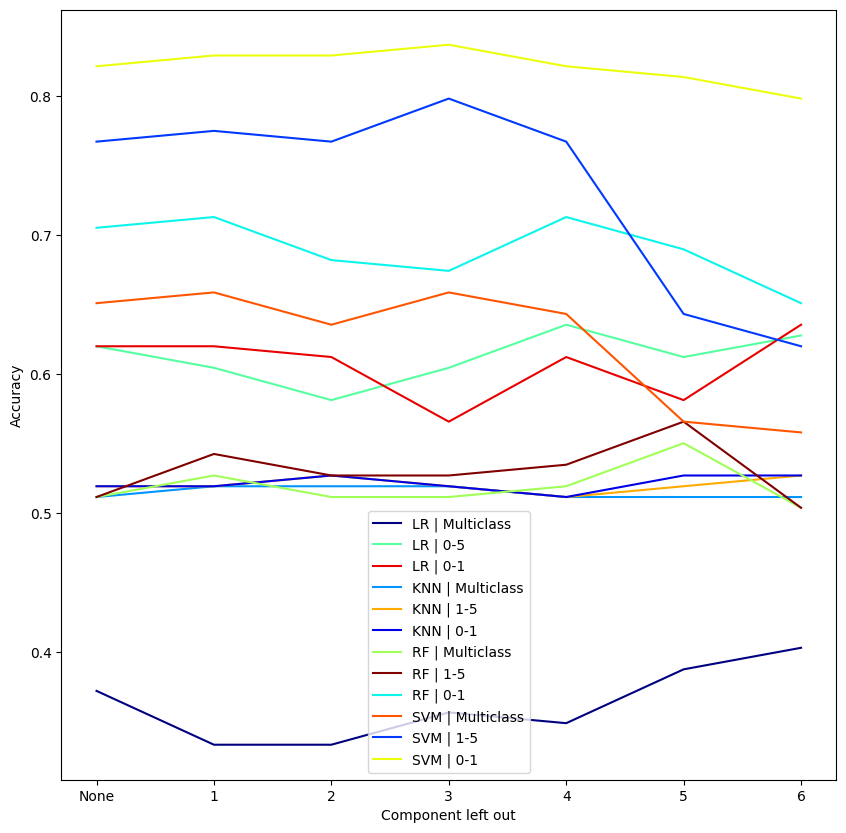

In [ ]:
plt.rcParams["figure.figsize"] = (10,10)

col = plt.cm.jet(np.linspace(0, 1, 12))

x = ['None', *range(1, 7)]
for i in range(12):
  c = col[np.mod(5*i, 12)]
  plt.plot(x, L[i, :], label=method(i), color=c)
plt.xlabel('Component left out')
plt.ylabel('Accuracy')
plt.legend()

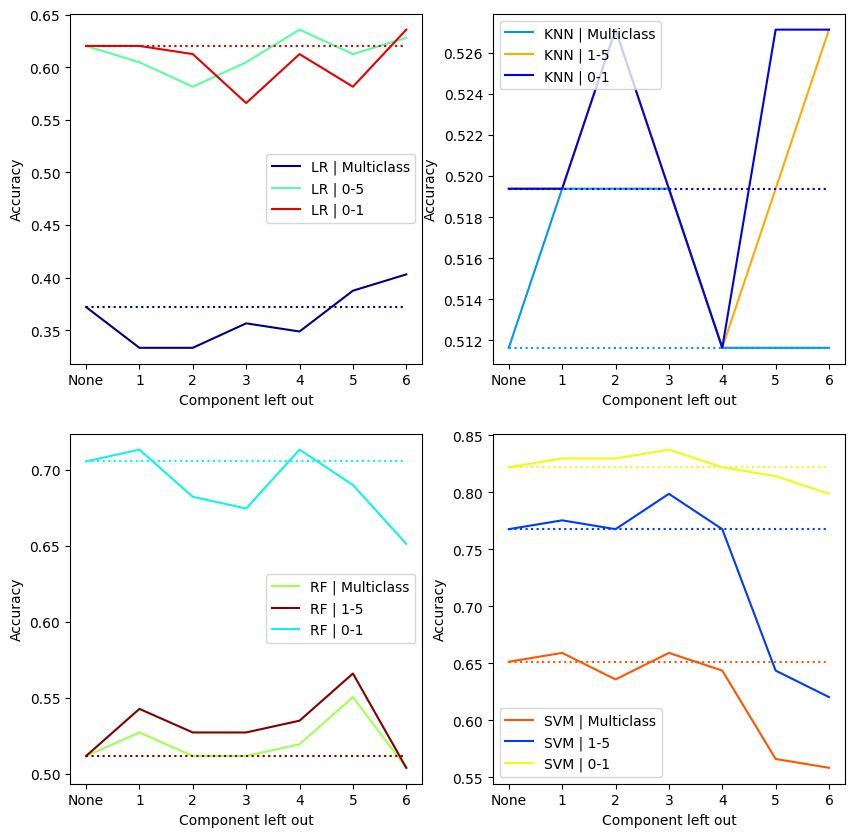

In [ ]:
plt.rcParams["figure.figsize"] = (10,10)

col = plt.cm.jet(np.linspace(0, 1, 12))

x = ['None', *range(1, 7)]
c = [col[np.mod(5*i, 12)] for i in range(12)]

for i in range(4):
  for j in range(3):
    k = 3*i+j
    plt.subplot(2, 2, i+1)
    plt.plot(x, L[k, :], label=method(k), color=c[k])
    plt.plot(x, [L[k, 0] for _ in range(7)], color=c[k], linestyle='dotted')
  plt.legend()
  plt.xlabel('Component left out')
  plt.ylabel('Accuracy')
plt.show()

In [ ]:
L0 = np.array([[(100*(L[i, j] - L[i, 0]*(j>0))).round(2) for j in range(7)] for i in range(12)]).reshape([12, 7])
L0 = pd.DataFrame(L0, columns=x, index=[method(i) for i in range(12)])
display(L0)

,None,1,2,3,4,5,6
LR | Multiclass,37.21,-3.88,-3.88,-1.55,-2.33,1.55,3.10
LR | 0-5,62.02,-1.55,-3.88,-1.55,1.55,-0.78,0.78
LR | 0-1,62.02,0.00,-0.78,-5.43,-0.78,-3.88,1.55
KNN | Multiclass,51.16,0.78,0.78,0.78,0.00,0.00,0.00
KNN | 1-5,51.94,0.00,0.78,0.00,-0.78,0.00,0.78
KNN | 0-1,51.94,0.00,0.78,0.00,-0.78,0.78,0.78
RF | Multiclass,51.16,1.55,0.00,0.00,0.78,3.88,-0.78
RF | 1-5,51.16,3.10,1.55,1.55,2.33,5.43,-0.78
RF | 0-1,70.54,0.78,-2.33,-3.10,0.78,-1.55,-5.43
SVM | Multiclass,65.12,0.78,-1.55,0.78,-0.78,-8.53,-9.30


## Reduced data

In [ ]:
R = np.zeros([12, 7])

for j in range(7):
  X, y, Z, w, n_train, n_test = reduce(rescale=True, hold_out = j-1)
  y1 = (y == 1)
  w1 = (w == 1)

  logr = linear_model.LogisticRegression(max_iter=100)
  logr.fit(X,y)
  pred = logr.predict(Z)
  R[0, j] = acc(w, pred)
  R[1, j] = acc(w1, (pred==1))
  logr.fit(X,y1)
  pred = logr.predict(Z)
  R[2, j] = acc(w1, pred)

  KNN = knn(5, weights='distance')
  KNN.fit(X, y)
  pred = KNN.predict(Z)
  R[3, j] = acc(w, pred)
  R[4, j] = acc(w1, (pred==1))
  KNN.fit(X, y1)
  pred = KNN.predict(Z)
  R[5, j] = acc(w1, pred)

  RF = RandomForestClassifier(n_estimators = 100, max_depth=5, random_state=0)
  RF.fit(X, y)
  pred = RF.predict(Z)
  R[6, j] = acc(w, pred)
  R[7, j] = acc(w1, (pred==1))
  RF.fit(X, y1)
  pred = RF.predict(Z)
  R[8, j] = acc(w1, pred)

  SVM=svm.SVC()
  SVM.fit(X, y)
  pred = SVM.predict(Z)
  R[9, j] = acc(w, pred)
  R[10, j] = acc(w1, (pred==1))
  SVM.fit(X, y1)
  pred = SVM.predict(Z)
  R[11, j] = acc(w1, pred)

  print(j)

0
1
2
3
4
5
6


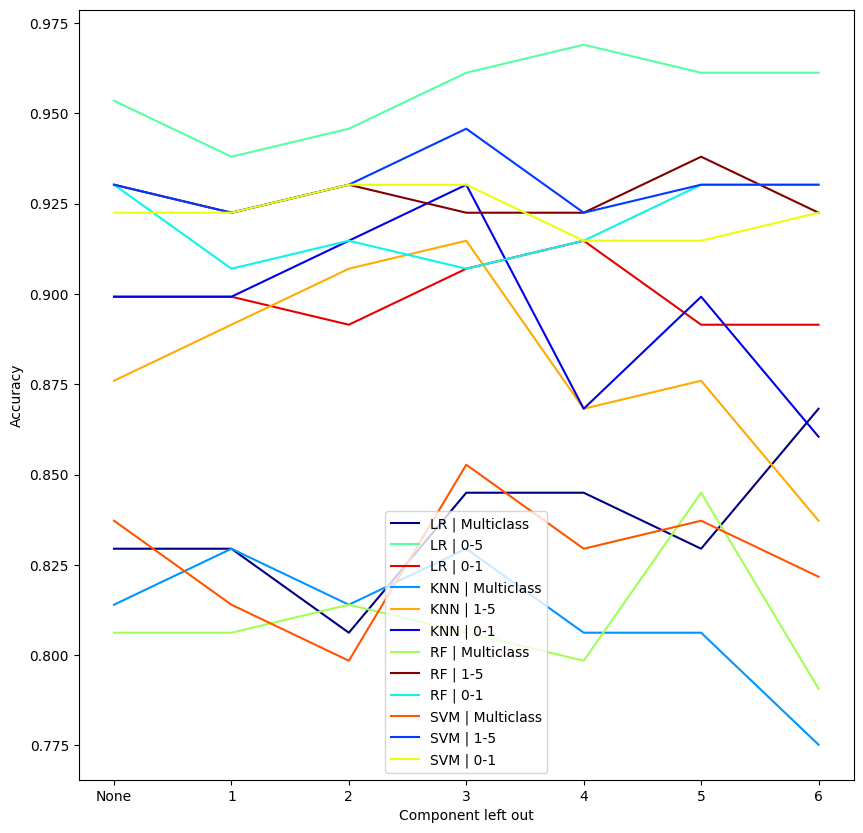

In [ ]:
plt.rcParams["figure.figsize"] = (10,10)

col = plt.cm.jet(np.linspace(0, 1, 12))

x = ['None', *range(1, 7)]
for i in range(12):
  c = col[np.mod(5*i, 12)]
  plt.plot(x, R[i, :], label=method(i), color=c)
plt.xlabel('Component left out')
plt.ylabel('Accuracy')
plt.legend()

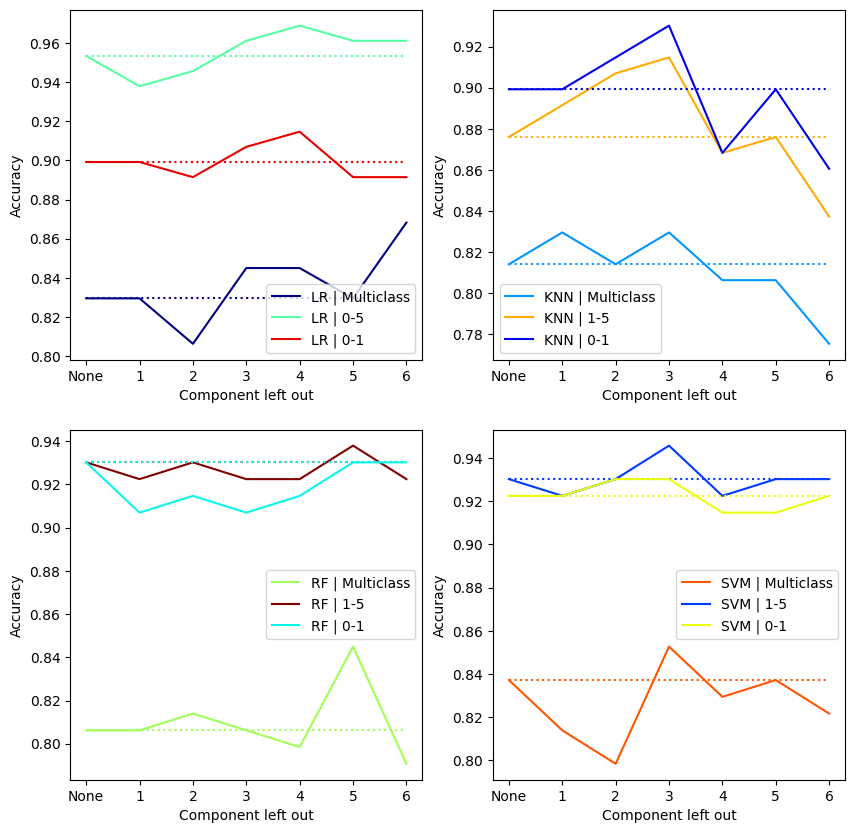

In [ ]:
plt.rcParams["figure.figsize"] = (10,10)

col = plt.cm.jet(np.linspace(0, 1, 12))

x = ['None', *range(1, 7)]
c = [col[np.mod(5*i, 12)] for i in range(12)]

for i in range(4):
  for j in range(3):
    k = 3*i+j
    plt.subplot(2, 2, i+1)
    plt.plot(x, R[k, :], label=method(k), color=c[k])
    plt.plot(x, [R[k, 0] for _ in range(7)], color=c[k], linestyle='dotted')
  plt.legend()
  plt.xlabel('Component left out')
  plt.ylabel('Accuracy')
plt.show()

In [ ]:
R0 = np.array([[(100*(R[i, j] - R[i, 0]*(j>0))).round(2) for j in range(7)] for i in range(12)]).reshape([12, 7])
R0 = pd.DataFrame(R0, columns=x, index=[method(i) for i in range(12)])
display(R0)

,None,1,2,3,4,5,6
LR | Multiclass,82.95,0.00,-2.33,1.55,1.55,0.00,3.88
LR | 0-5,95.35,-1.55,-0.78,0.78,1.55,0.78,0.78
LR | 0-1,89.92,0.00,-0.78,0.78,1.55,-0.78,-0.78
KNN | Multiclass,81.40,1.55,0.00,1.55,-0.78,-0.78,-3.88
KNN | 1-5,87.60,1.55,3.10,3.88,-0.78,0.00,-3.88
KNN | 0-1,89.92,0.00,1.55,3.10,-3.10,0.00,-3.88
RF | Multiclass,80.62,0.00,0.78,0.00,-0.78,3.88,-1.55
RF | 1-5,93.02,-0.78,0.00,-0.78,-0.78,0.78,-0.78
RF | 0-1,93.02,-2.33,-1.55,-2.33,-1.55,0.00,0.00
SVM | Multiclass,83.72,-2.33,-3.88,1.55,-0.78,0.00,-1.55
